Finds when customers charge: which hours and days are busiest, whether demand changes with the seasons, and how patterns differ by region and charger type, to guide pricing, staffing and supply decisions. Station numbers grew from 8 to 33 over the period, so all comparisons use sessions per station, not raw session counts.  
Definitions used throughout:  
* **Sessions per station per day:** the number of sessions on a day divided by the number of stations open that day. It removes the effect of new stations opening.
* **Peak, shoulder and off-peak hours:** hours of the day grouped by their share of sessions. Peak hours have at least 1.5 times the average hourly share, and off-peak hours have at most half the average.
* **Weekday and weekend:** Monday to Friday against Saturday and Sunday.
* **Seasonal index:** a month's average sessions per station divided by the average over all months (1.00 means an average month).
* **Premium window:** the hours (16:00 to 20:59) in which the price per kWh is higher.
* **Time-of-use pricing:** charging different prices at different times of day.

**Set up**  
Libraries are imported, and the input path is set. show() saves every chart as a PNG in a figures folder (for the repo) and then displays it.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 50, 'axes.titlesize': 12, 'axes.labelsize': 10})

DATA_PATH = '/kaggle/input/datasets/sanyazuberi/ev-charging-raw-dataset/Copy of ev_charging_dataset.xlsx'
OUT = '/kaggle/working'
FIG_DIR = f'{OUT}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def show(name):
    """Save the current figure as a PNG (for the repo) and display it."""
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=100, bbox_inches='tight')
    plt.show()

**Loading the data**  
All three sheets are used: sessions (when and where customers charge, and what they pay), stations (region and activation year) and chargers (charger type).

In [2]:
stations = pd.read_excel(DATA_PATH, sheet_name='stations')
chargers = pd.read_excel(DATA_PATH, sheet_name='chargers')
sessions = pd.read_excel(DATA_PATH, sheet_name='sessions')

for c in ['start_timestamp', 'end_timestamp']:
    sessions[c] = pd.to_datetime(sessions[c])

print(f"stations: {len(stations)} | chargers: {len(chargers)} | sessions: {len(sessions):,}")
print(sessions['start_timestamp'].min().date(), 'to', sessions['start_timestamp'].max().date())

stations: 33 | chargers: 199 | sessions: 294,024
2022-01-01 to 2024-12-31


The data has 33 stations, 199 chargers and 294,024 sessions, from 1 January 2022 to 31 December 2024.

**Preparing time fields**  
Each session gets its hour, day of the week (0 is Monday), month, year, weekend flag and season. A daily table is also built with the number of sessions and the number of stations open each day (a station counts as open from 1 January of its activation year). Dividing one by the other gives sessions per station per day, which is used for every comparison over time.

In [3]:
s = sessions.copy()
s['date'] = s['start_timestamp'].dt.normalize()
s['hour'] = s['start_timestamp'].dt.hour
s['dow'] = s['start_timestamp'].dt.dayofweek            # 0 = Monday
s['month'] = s['start_timestamp'].dt.month
s['year'] = s['start_timestamp'].dt.year
s['is_weekend'] = s['dow'] >= 5
SEASONS = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
           6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
s['season'] = s['month'].map(SEASONS)

print('Missing values:', int(s.isna().sum().sum()))
print('Price per kWh (min / mean / max):', s['price_per_kwh'].agg(['min', 'mean', 'max']).round(3).to_dict())
print('Total cost equals price x energy for', f"{((s['price_per_kwh'] * s['energy_kwh'] - s['total_cost']).abs() < 0.02).mean():.1%}", 'of sessions')

days = pd.date_range('2022-01-01', '2024-12-31')
stations['activation_start'] = pd.to_datetime(stations['activation_year'].astype(str) + '-01-01')
active = pd.Series([(stations['activation_start'] <= d).sum() for d in days], index=days)
daily = pd.DataFrame({'sessions': s.groupby('date').size().reindex(days, fill_value=0), 'stations': active})
daily['sessions_per_station'] = daily['sessions'] / daily['stations']
daily['dow'] = daily.index.dayofweek
daily['month'] = daily.index.month
daily['year'] = daily.index.year

print('Days with no sessions:', (daily['sessions'] == 0).sum(), 'of', len(daily))
by_year = daily.groupby('year').agg(stations_at_year_end=('stations', 'max'), sessions=('sessions', 'sum'),
                                    sessions_per_station_day=('sessions_per_station', 'mean'))
display(by_year.round(2))

Missing values: 0
Price per kWh (min / mean / max): {'min': 0.45, 'mean': 0.592, 'max': 0.8}
Total cost equals price x energy for 100.0% of sessions
Days with no sessions: 0 of 1096


,stations_at_year_end,sessions,sessions_per_station_day
year,,,
2022,8,40640,13.92
2023,17,86132,13.88
2024,33,167252,13.85


There are no missing values, and total cost equals price per kWh times energy for every session. Price per kWh ranges from 0.45 to 0.80 (mean 0.592). Every one of the 1,096 days has sessions.
Total sessions rose from 40,640 in 2022 to 86,132 in 2023 and 167,252 in 2024, but only because the number of stations grew from 8 to 17 to 33. Sessions per station per day stayed almost unchanged at 13.92, 13.88 and 13.85. Every comparison over time therefore uses sessions per station.

**Hourly demand**  
Each hour's share of all sessions is calculated. Hours are then grouped into three tiers by comparing each share with the average hourly share of 4.17% (100% across 24 hours): peak hours have at least 1.5 times the average, off-peak hours have at most half, and the rest are shoulder hours. The second chart compares the weekday and weekend profiles.

Peak: 8 hours | share of sessions 61.8%
Shoulder: 7 hours | share of sessions 28.1%
Off-peak: 9 hours | share of sessions 10.0%
Hours in each tier: {'Peak': [9, 10, 11, 12, 13, 14, 15, 16], 'Shoulder': [6, 7, 8, 17, 18, 19, 20], 'Off-peak': [0, 1, 2, 3, 4, 5, 21, 22, 23]}
Busiest hours (share, %): {10: 8.2, 13: 8.2, 14: 8.2, 11: 8.2, 12: 8.1}
Quietest hours (share, %): {3: 0.9, 23: 0.9, 22: 0.9, 1: 0.9, 4: 0.9}
Largest weekday vs weekend difference in any hour (percentage points): 0.34


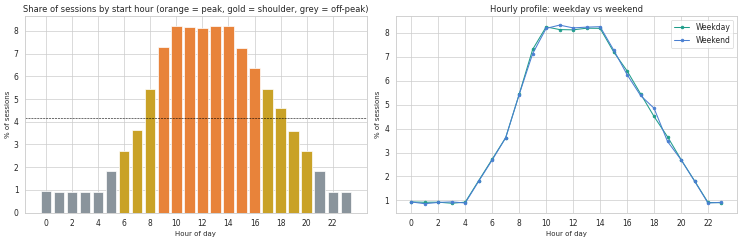

In [4]:
hour_share = s.groupby('hour').size() / len(s) * 100
AVG = 100 / 24
tier = pd.Series(np.where(hour_share >= 1.5 * AVG, 'Peak', np.where(hour_share <= 0.5 * AVG, 'Off-peak', 'Shoulder')),
                 index=hour_share.index)
for t in ['Peak', 'Shoulder', 'Off-peak']:
    hrs = hour_share[tier == t]
    print(f"{t}: {len(hrs)} hours | share of sessions {hrs.sum():.1f}%")
print('Hours in each tier:', {t: hour_share[tier == t].index.tolist() for t in ['Peak', 'Shoulder', 'Off-peak']})
print('Busiest hours (share, %):', hour_share.sort_values(ascending=False).head(5).round(1).to_dict())
print('Quietest hours (share, %):', hour_share.sort_values().head(5).round(1).to_dict())

wk = s.groupby(['is_weekend', 'hour']).size().unstack(0)
wk = wk / wk.sum() * 100
wk.columns = ['Weekday', 'Weekend']
print('Largest weekday vs weekend difference in any hour (percentage points):', round((wk['Weekday'] - wk['Weekend']).abs().max(), 2))

colors = tier.map({'Peak': '#e8833a', 'Shoulder': '#c9a227', 'Off-peak': '#8a949c'})
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(hour_share.index, hour_share.values, color=colors)
ax[0].axhline(AVG, color='black', linestyle='--', linewidth=0.8)
ax[0].set_title('Share of sessions by start hour (orange = peak, gold = shoulder, grey = off-peak)')
ax[0].set_xlabel('Hour of day'); ax[0].set_ylabel('% of sessions'); ax[0].set_xticks(range(0, 24, 2))
wk.plot(ax=ax[1], color=['#1f9d8a', '#4a7fd1'], marker='o', markersize=4)
ax[1].set_title('Hourly profile: weekday vs weekend')
ax[1].set_xlabel('Hour of day'); ax[1].set_ylabel('% of sessions'); ax[1].set_xticks(range(0, 24, 2))
show('01_hourly_demand')

Demand is concentrated in the middle of the day. The 8 peak hours (09:00 to 16:59) carry 61.8% of all sessions, the 7 shoulder hours (06:00 to 08:59 and 17:00 to 20:59) carry 28.1%, and the 9 off-peak hours (21:00 to 05:59) carry only 10.0%.
The busiest hours are 10:00 to 14:59, each taking 8.1% to 8.2% of sessions. The quietest are 22:00 to 04:59, each taking 0.9%. The weekday and weekend profiles have almost exactly the same shape, differing by at most 0.34 percentage points in any hour, so weekends are quieter overall but not busier at different hours.

**Weekly demand**  
Sessions per station per day are compared across the days of the week, and across years to check the pattern is stable. A heatmap then shows how many sessions start per station in each hour of each weekday, which is the demand to plan staffing and supply around.

,mean,std
Mon,15.05,0.86
Tue,15.06,0.87
Wed,14.95,0.82
Thu,14.91,0.91
Fri,15.11,0.83
Sat,11.06,0.70
Sun,11.04,0.65


Weekday 15.02 vs weekend 11.05 sessions per station per day | weekend is 26% lower
Weekday share of all sessions: 77.3%
Weekend / weekday ratio by year: {2022: 0.742, 2023: 0.735, 2024: 0.73}


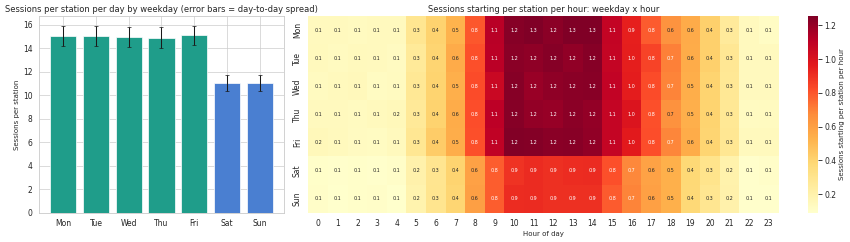

Busiest cell: ('Mon', np.int32(13)) 1.25 | quietest: ('Sun', np.int32(4)) 0.09
Weekday 10:00-14:59 mean: 1.23 | weekend 00:00-04:59 mean: 0.1


In [5]:
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
by_dow = daily.groupby('dow')['sessions_per_station'].agg(['mean', 'std'])
by_dow.index = dow_names
display(by_dow.round(2))

wd = daily.loc[daily['dow'] < 5, 'sessions_per_station'].mean()
we = daily.loc[daily['dow'] >= 5, 'sessions_per_station'].mean()
print(f"Weekday {wd:.2f} vs weekend {we:.2f} sessions per station per day | weekend is {1 - we / wd:.0%} lower")
print('Weekday share of all sessions:', f"{(~s['is_weekend']).mean():.1%}")
ratio_by_year = daily.groupby('year').apply(lambda d: d.loc[d['dow'] >= 5, 'sessions_per_station'].mean()
                                            / d.loc[d['dow'] < 5, 'sessions_per_station'].mean())
print('Weekend / weekday ratio by year:', ratio_by_year.round(3).to_dict())

station_days = daily.groupby('dow')['stations'].sum()
heat = s.groupby(['dow', 'hour']).size().unstack().div(station_days, axis=0)
heat.index = dow_names

fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 2.4]})
ax[0].bar(by_dow.index, by_dow['mean'], yerr=by_dow['std'], color=['#1f9d8a'] * 5 + ['#4a7fd1'] * 2, capsize=3)
ax[0].set_title('Sessions per station per day by weekday (error bars = day-to-day spread)')
ax[0].set_ylabel('Sessions per station')
sns.heatmap(heat, annot=True, fmt='.1f', cmap='YlOrRd', annot_kws={'size': 7}, ax=ax[1],
            cbar_kws={'label': 'Sessions starting per station per hour'})
ax[1].set_title('Sessions starting per station per hour: weekday x hour')
ax[1].set_xlabel('Hour of day'); ax[1].set_ylabel('')
show('02_weekly_demand')

print('Busiest cell:', heat.stack().idxmax(), round(heat.stack().max(), 2), '| quietest:', heat.stack().idxmin(), round(heat.stack().min(), 2))
print('Weekday 10:00-14:59 mean:', round(heat.loc[dow_names[:5], 10:14].values.mean(), 2),
      '| weekend 00:00-04:59 mean:', round(heat.loc[['Sat', 'Sun'], 0:4].values.mean(), 3))

The five weekdays are almost identical, at 14.9 to 15.1 sessions per station per day, and the two weekend days are almost identical too, at 11.0 to 11.1. Weekends are 26% lower than weekdays (11.05 against 15.02), and weekdays carry 77.3% of all sessions. The gap is stable over time: the weekend-to-weekday ratio was 0.742 in 2022, 0.735 in 2023 and 0.730 in 2024.
The heatmap shows the busiest time is Monday at 13:00, with 1.25 sessions starting per station per hour, and weekdays between 10:00 and 14:59 average 1.23. The quietest time is Sunday at 04:00, with 0.09 sessions per station per hour, and weekends between 00:00 and 04:59 average 0.10, which is about one session starting per station every 10 hours.

**Peak and off-peak insights**  
For each tier of hours (peak, shoulder, off-peak), the table shows its share of sessions, energy and revenue, and how many sessions start per station per hour on weekdays and weekends. The number of chargers in use per station is estimated by multiplying the weekday session rate by the average session length (35 minutes), which is how many chargers are busy on average. It is then compared with the average of 6 chargers per station.

In [6]:
s['tier'] = s['hour'].map(tier)
tot = s.agg({'session_id': 'size', 'energy_kwh': 'sum', 'total_cost': 'sum'})
tiers = s.groupby('tier').agg(sessions=('session_id', 'size'), kwh=('energy_kwh', 'sum'), revenue=('total_cost', 'sum'))
insight = pd.DataFrame({
    'hours'            : tier.value_counts(),
    'share_of_sessions': tiers['sessions'] / tot['session_id'] * 100,
    'share_of_energy'  : tiers['kwh'] / tot['energy_kwh'] * 100,
    'share_of_revenue' : tiers['revenue'] / tot['total_cost'] * 100}).loc[['Peak', 'Shoulder', 'Off-peak']]

avg_hours = s['session_duration_minutes'].mean() / 60
chargers_per_station = len(chargers) / len(stations)
rows = {}
for t in ['Peak', 'Shoulder', 'Off-peak']:
    hrs = tier[tier == t].index
    rows[t] = {'wkday_sessions_per_station_hour': heat.loc[dow_names[:5], hrs].values.mean(),
               'wkend_sessions_per_station_hour': heat.loc[['Sat', 'Sun'], hrs].values.mean()}
insight = insight.join(pd.DataFrame(rows).T)
insight['wkday_chargers_in_use'] = insight['wkday_sessions_per_station_hour'] * avg_hours
insight['wkday_pct_of_chargers_in_use'] = insight['wkday_chargers_in_use'] / chargers_per_station * 100
display(insight.round(2))
print(f"Average session {avg_hours * 60:.1f} minutes | chargers per station {chargers_per_station:.2f}")
print('Busiest cell in chargers in use:', round(heat.stack().max() * avg_hours, 2), 'per station =',
      f"{heat.stack().max() * avg_hours / chargers_per_station:.0%} of chargers")

,hours,share_of_sessions,share_of_energy,share_of_revenue,wkday_sessions_per_station_hour,wkend_sessions_per_station_hour,wkday_chargers_in_use,wkday_pct_of_chargers_in_use
Peak,8,61.84,61.85,61.12,1.16,0.85,0.68,11.25
Shoulder,7,28.11,28.10,29.06,0.60,0.44,0.35,5.85
Off-peak,9,10.05,10.05,9.82,0.17,0.12,0.10,1.63


Average session 35.1 minutes | chargers per station 6.03
Busiest cell in chargers in use: 0.73 per station = 12% of chargers


Peak hours (09:00 to 16:59) carry 62% of sessions and energy and 61.1% of revenue. Shoulder hours carry 28.1% of sessions and 29.1% of revenue, and off-peak hours (21:00 to 05:59) carry 10.0% of sessions and 9.8% of revenue. Shoulder hours earn a slightly larger share of revenue than of sessions because most of the price premium falls in them.
During peak hours, 1.16 sessions start per station per hour on weekdays (0.85 on weekends). That means about 0.68 chargers are in use per station, or 11.3% of the 6 chargers an average station has. Even the busiest cell (Monday 13:00) has only about 0.73 chargers in use, or 12%, close to the 11.5% found in your charger utilisation analysis. In shoulder hours the figure is 0.35 chargers (5.9%), and in off-peak hours 0.10 (1.6%).
Chargers are therefore idle most of the time even at the busiest hour. The quietest window is overnight at weekends, when a station sees a new session about once every 10 hours.

**Seasonal trends**  
Raw monthly sessions grow because stations open, so seasonality is tested on sessions per station per day, adjusted for the day of the week (each day divided by the average for its weekday). The seasonal index is each month's average divided by the overall average, with a 95% interval. A one-way test checks whether month has any effect, seasons are compared, and a trend line is fitted over the three years. Christmas Day and New Year's Day are also checked against a normal day of the same weekday.

One-way test of month effect (weekday-adjusted sessions per station): F = 0.56, p = 0.86
Monthly index range: 0.988 to 1.006
Season index: {'Autumn': 0.997, 'Spring': 1.0, 'Summer': 1.001, 'Winter': 1.002}
Trend in weekday-adjusted sessions per station: -0.32% per year (p = 0.12)


year,2022,2023,2024
month,,,
1,13.69,14.04,13.97
2,13.93,13.93,14.01
3,14.10,14.07,13.57
4,13.95,13.56,13.84
5,14.10,13.90,13.98
6,13.89,13.98,13.74
7,13.79,13.72,13.89
8,14.19,14.04,13.72
9,13.66,13.80,13.67


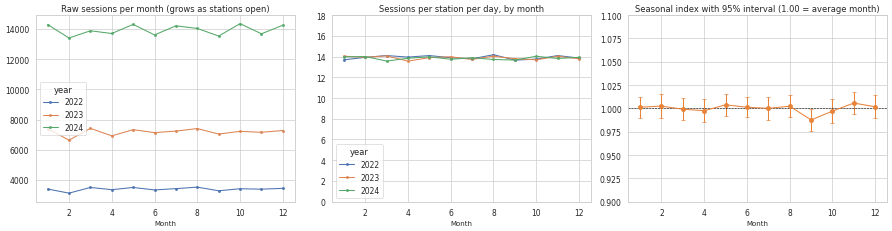

2022-12-25 Sun 0.95 | 2023-12-25 Mon 0.99 | 2024-12-25 Wed 1.0 | 2022-01-01 Sat 1.06 | 2023-01-01 Sun 0.97 | 2024-01-01 Mon 1.04 | 
Day-to-day spread on weekdays (std / mean): 5.7%
Day-to-day spread on weekends (std / mean): 6.1%


In [7]:
from scipy import stats

d = daily.copy()
d['dow_adj'] = d['sessions_per_station'] / d.groupby('dow')['sessions_per_station'].transform('mean')
month_idx = d.groupby('month')['dow_adj'].agg(['mean', 'std', 'count'])
month_idx['index'] = month_idx['mean'] / month_idx['mean'].mean()
month_idx['ci95'] = 1.96 * month_idx['std'] / np.sqrt(month_idx['count']) / month_idx['mean'].mean()

f_stat, p_val = stats.f_oneway(*[g['dow_adj'].values for _, g in d.groupby('month')])
print(f"One-way test of month effect (weekday-adjusted sessions per station): F = {f_stat:.2f}, p = {p_val:.2f}")
print('Monthly index range:', round(month_idx['index'].min(), 3), 'to', round(month_idx['index'].max(), 3))
season_idx = d.assign(season=d['month'].map(SEASONS)).groupby('season')['dow_adj'].mean()
print('Season index:', (season_idx / d['dow_adj'].mean()).round(3).to_dict())
trend = stats.linregress(np.arange(len(d)), d['dow_adj'])
print(f"Trend in weekday-adjusted sessions per station: {trend.slope * 365 / d['dow_adj'].mean():+.2%} per year (p = {trend.pvalue:.2f})")

monthly_raw = s.groupby(['year', 'month']).size().unstack(0)
monthly_ps = d.pivot_table(index='month', columns='year', values='sessions_per_station')
display(monthly_ps.round(2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
monthly_raw.plot(ax=ax[0], marker='o', markersize=3)
ax[0].set_title('Raw sessions per month (grows as stations open)'); ax[0].set_xlabel('Month')
monthly_ps.plot(ax=ax[1], marker='o', markersize=3)
ax[1].set_title('Sessions per station per day, by month'); ax[1].set_xlabel('Month'); ax[1].set_ylim(0, 18)
ax[2].errorbar(month_idx.index, month_idx['index'], yerr=month_idx['ci95'], fmt='o-', color='#e8833a', capsize=3)
ax[2].axhline(1, color='black', linestyle='--', linewidth=0.8); ax[2].set_ylim(0.9, 1.1)
ax[2].set_title('Seasonal index with 95% interval (1.00 = average month)'); ax[2].set_xlabel('Month')
show('03_seasonal_trends')

for date in ['2022-12-25', '2023-12-25', '2024-12-25', '2022-01-01', '2023-01-01', '2024-01-01']:
    t = pd.Timestamp(date)
    r = d.loc[t, 'sessions_per_station'] / d.loc[d['dow'] == t.dayofweek, 'sessions_per_station'].mean()
    print(date, t.day_name()[:3], round(r, 2), end=' | ')
print()
for name, mask in [('weekdays', daily['dow'] < 5), ('weekends', daily['dow'] >= 5)]:
    x = daily.loc[mask, 'sessions_per_station']
    print(f"Day-to-day spread on {name} (std / mean): {x.std() / x.mean():.1%}")

There is no seasonality. The monthly index runs from 0.988 to 1.006, a range of under 2%, and the test finds no month effect (F = 0.56, p = 0.86). The seasons are indistinguishable (winter 1.002, summer 1.001, spring 1.000, autumn 0.997). The trend over the three years is -0.32% a year, which is not statistically significant (p = 0.12). Every month in the table of sessions per station per day sits between 13.6 and 14.2, whatever the year.
The first chart shows why the raw monthly volumes look like growth: they are flat within each year, at about 3,400 sessions a month in 2022, 7,200 in 2023 and 13,900 in 2024, and step up at the start of each year when the new year's stations are counted as open. Per station, there is nothing left.
Public holidays show no dip either. Christmas Day and New Year's Day ranged from 0.95 to 1.06 of a normal day of the same weekday, which is within the usual day-to-day spread of 5.7% on weekdays and 6.1% on weekends.

**Pricing against demand**  
Prices are checked for a time-of-use structure and compared with demand, in three steps. First, how the price differs inside and outside the premium window (16:00 to 20:59) and across years. Second, whether demand responded when the price changed between years. Third, how well the premium window lines up with the demand peak. A what-if then shows the effect of moving the premium to the five busiest hours, assuming customers do not change their behaviour, together with the fall in sessions that would cancel the gain.

,offpeak_price,premium_price,premium_markup_pct,avg_price,sessions_per_station_day,revenue_per_station_day
year,,,,,,
2022,0.500,0.551,10.121,0.511,13.918,352.319
2023,0.625,0.687,10.009,0.639,13.881,417.047
2024,0.575,0.632,9.958,0.588,13.848,377.095


Premium-window price, weekday vs weekend: {False: 0.637, True: 0.637}


,price_change,demand_change,implied_elasticity
year,,,
2022,NaN,NaN,NaN
2023,0.25,-0.003,-0.011
2024,-0.08,-0.002,0.030


Premium window 16:00-20:59: 22.7% of sessions, 24.4% of revenue
Peak-tier hours inside the premium window: [16]
Markup 1.100 | revenue share 10:00-14:59: 40.0%, 16:00-20:59: 24.4%
Moving the premium to 10:00-14:59 changes revenue by +1.8% if demand does not respond
Break-even fall in 10:00-14:59 sessions: 4.1%


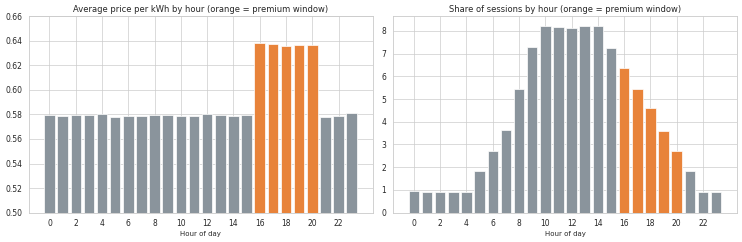

In [8]:
s['premium'] = s['hour'].between(16, 20)
price = s.pivot_table(index='year', columns='premium', values='price_per_kwh', aggfunc='mean')
price.columns = ['offpeak_price', 'premium_price']
price['premium_markup_pct'] = (price['premium_price'] / price['offpeak_price'] - 1) * 100
price['avg_price'] = s.groupby('year')['price_per_kwh'].mean()
price['sessions_per_station_day'] = daily.groupby('year')['sessions_per_station'].mean()
price['revenue_per_station_day'] = s.groupby('year')['total_cost'].sum() / daily.groupby('year')['stations'].sum()
display(price.round(3))
print('Premium-window price, weekday vs weekend:', s[s['premium']].groupby('is_weekend')['price_per_kwh'].mean().round(3).to_dict())

chg_price = price['avg_price'].pct_change()
chg_demand = price['sessions_per_station_day'].pct_change()
display(pd.DataFrame({'price_change': chg_price, 'demand_change': chg_demand, 'implied_elasticity': chg_demand / chg_price}).round(3))

prem = s[s['premium']]
print(f"Premium window 16:00-20:59: {len(prem) / len(s):.1%} of sessions, {prem['total_cost'].sum() / s['total_cost'].sum():.1%} of revenue")
print('Peak-tier hours inside the premium window:', [h for h in tier[tier == 'Peak'].index if 16 <= h <= 20])

# what-if: move the premium to 10:00-14:59 (no demand response assumed)
MARKUP = price['premium_markup_pct'].mean() / 100 + 1
rev_h = s.groupby('hour')['total_cost'].sum()
R_new, R_old = rev_h.loc[10:14].sum(), rev_h.loc[16:20].sum()
delta = (MARKUP - 1) * R_new - (1 - 1 / MARKUP) * R_old
breakeven = 1 - (1 + (1 - 1 / MARKUP) * R_old / R_new) / MARKUP
print(f"Markup {MARKUP:.3f} | revenue share 10:00-14:59: {R_new / rev_h.sum():.1%}, 16:00-20:59: {R_old / rev_h.sum():.1%}")
print(f"Moving the premium to 10:00-14:59 changes revenue by {delta / rev_h.sum():+.1%} if demand does not respond")
print(f"Break-even fall in 10:00-14:59 sessions: {breakeven:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ph = s.groupby('hour')['price_per_kwh'].mean()
ax[0].bar(ph.index, ph.values, color=np.where(ph.index.isin(range(16, 21)), '#e8833a', '#8a949c'))
ax[0].set_ylim(0.5, 0.66); ax[0].set_title('Average price per kWh by hour (orange = premium window)')
ax[0].set_xlabel('Hour of day'); ax[0].set_xticks(range(0, 24, 2))
ax[1].bar(hour_share.index, hour_share.values, color=np.where(hour_share.index.isin(range(16, 21)), '#e8833a', '#8a949c'))
ax[1].set_title('Share of sessions by hour (orange = premium window)')
ax[1].set_xlabel('Hour of day'); ax[1].set_xticks(range(0, 24, 2))
show('04_price_vs_demand')

**Price structure.** The network uses time-of-use pricing: a premium of about 10% (10.1%, 10.0% and 10.0% in the three years) applies from 16:00 to 20:59, and it is the same on weekdays and weekends (0.637 per kWh in both). The base price changed by year: 0.500 in 2022, 0.625 in 2023 and 0.575 in 2024.
**Demand did not respond to price.** The average price rose 25% in 2023 and fell 8% in 2024, yet sessions per station per day were 13.92, 13.88 and 13.85, an implied elasticity of -0.01 in 2023 and +0.03 in 2024, with no consistent direction. Revenue per station per day followed the price instead: 352, 417 and 377. This rests on three yearly price points, so it shows no visible response, not that customers are insensitive to price.  
**The premium window misses the demand peak.** It covers 22.7% of sessions and brings in 24.4% of revenue, while the peak tier (09:00 to 16:59, 61.8% of sessions) overlaps it in one hour only, 16:00. Most of the busiest hours are charged the base price.  
**What-if.** Moving the 10% premium to 10:00-14:59 (41.0% of sessions, 40.0% of revenue) and removing it from 16:00-20:59 (24.4% of revenue) would raise revenue by 1.8% if customers did not change their behaviour. The gain disappears if sessions in 10:00-14:59 fall by more than 4.1%. Since no response to price can be seen in this data, it cannot say whether the move would shift any demand out of the peak.

**Behaviour by region**  
For each region, the table shows sessions per station per day, the weekend-to-weekday ratio, the share of sessions in peak hours and in the premium window, a price index (each session's price divided by the network average for its year, so regions that opened in a higher-priced year are not misread), and energy per session. The weekend-to-weekday ratio is the sessions per day on a weekend day divided by the sessions per day on a weekday. Two chi-square tests check whether the hourly pattern and the weekend share differ between regions by more than chance (a p-value above 0.05 means no detectable difference).

,stations,sessions_per_station_day,weekend_weekday_ratio,peak_tier_share,premium_window_share,price_index,kwh_per_session
London,5,13.935,0.720,61.673,22.939,1.001,48.530
Midlands,5,13.844,0.736,61.993,22.819,1.000,50.925
North East,3,13.880,0.739,61.398,22.484,1.000,45.930
North West,7,13.844,0.739,61.697,22.736,1.000,45.678
Scotland,3,13.836,0.723,62.148,23.244,1.000,46.784
South East,4,13.761,0.734,62.027,22.556,1.000,43.249
South West,3,13.863,0.740,62.054,22.565,0.999,51.988
Wales,1,13.897,0.719,62.201,22.453,1.000,32.978
Yorkshire & Humber,2,14.000,0.727,61.862,22.415,1.000,43.958


Network weekend / weekday ratio: 0.733
Region vs hour of day: chi-square p = 0.94 | region vs weekend: p = 0.69


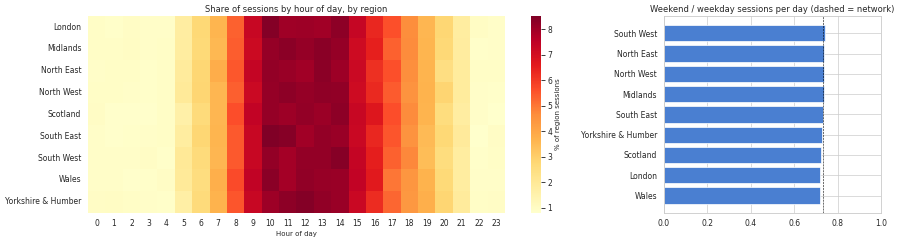

In [9]:
from scipy.stats import chi2_contingency

END = pd.Timestamp('2025-01-01')
station_days = stations.groupby('region')['activation_start'].apply(lambda x: (END - x).dt.days.sum())

def weekend_ratio(g):
    we = g['is_weekend'].mean()
    return (we / 2) / ((1 - we) / 5)          # sessions per weekend day / sessions per weekday

g = s.groupby('station_region')
region = pd.DataFrame({
    'stations'                : stations.groupby('region').size(),
    'sessions_per_station_day': g.size() / station_days,
    'weekend_weekday_ratio'   : g.apply(weekend_ratio),
    'peak_tier_share'         : g['tier'].apply(lambda x: (x == 'Peak').mean() * 100),
    'premium_window_share'    : g['premium'].mean() * 100,
    'price_index'             : (s['price_per_kwh'] / s.groupby('year')['price_per_kwh'].transform('mean')).groupby(s['station_region']).mean(),
    'kwh_per_session'         : g['energy_kwh'].mean()})
display(region.round(3))
print('Network weekend / weekday ratio:', round(weekend_ratio(s), 3))

chi_hour = chi2_contingency(pd.crosstab(s['station_region'], s['hour']))
chi_week = chi2_contingency(pd.crosstab(s['station_region'], s['is_weekend']))
print(f"Region vs hour of day: chi-square p = {chi_hour[1]:.2f} | region vs weekend: p = {chi_week[1]:.2f}")

region_hour = s.groupby(['station_region', 'hour']).size().unstack()
region_hour = region_hour.div(region_hour.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2.4, 1]})
sns.heatmap(region_hour, cmap='YlOrRd', ax=ax[0], cbar_kws={'label': '% of region sessions'})
ax[0].set_title('Share of sessions by hour of day, by region'); ax[0].set_xlabel('Hour of day'); ax[0].set_ylabel('')
r = region.sort_values('weekend_weekday_ratio')
ax[1].barh(r.index, r['weekend_weekday_ratio'], color='#4a7fd1')
ax[1].axvline(weekend_ratio(s), color='black', linestyle='--', linewidth=0.8)
ax[1].set_xlim(0, 1); ax[1].set_title('Weekend / weekday sessions per day (dashed = network)')
show('05_region_behaviour')

All nine regions behave the same way. Sessions per station per day are between 13.76 and 14.00, the weekend-to-weekday ratio between 0.72 and 0.74 (network 0.733), the peak-hour share between 61.4% and 62.2%, and the premium-window share between 22.4% and 23.2%. The price index is 1.00 in every region. The tests agree: the hourly pattern does not differ between regions (p = 0.94), nor does the weekend share (p = 0.69).  
The heatmap shows the same midday band in every row. The one thing that differs by region is energy per session, from 33.0 kWh in Wales to 52.0 kWh in South West, and that comes from the charger mix (Wales has only 50 kW chargers), not from timing.

**Behaviour by charger type**  
The same measures are compared for 50 kW, 150 kW and 300 kW chargers, plus session length, revenue per session and how busy a charger is during weekday peak hours (sessions starting per charger per peak hour, multiplied by the average session length). The hourly profiles are compared with chi-square tests, both hour by hour and grouped into the three tiers.

,chargers,sessions_per_charger_day,avg_duration_min,kwh_per_session,revenue_per_session,weekend_weekday_ratio,peak_tier_share,premium_window_share,price_index,weekday_peak_busy_pct
charger_type,,,,,,,,,,
DC_50kW,95,2.31,49.48,32.97,19.59,0.73,61.78,22.81,1.0,15.94
DC_150kW,69,2.29,24.50,48.96,28.95,0.73,61.91,22.58,1.0,7.81
DC_300kW,35,2.50,19.49,75.54,44.56,0.74,61.86,22.74,1.0,6.78


Charger type vs hour of day: p = 0.046 | vs peak / shoulder / off-peak tier: p = 0.97
Largest difference between charger types in any hour (percentage points): 0.42


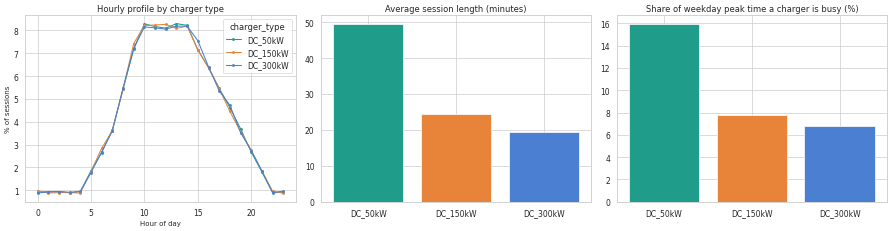

In [10]:
ch = chargers.merge(stations[['station_id', 'activation_start']], on='station_id')
ch['days'] = (END - ch['activation_start']).dt.days
all_days = pd.date_range('2022-01-01', '2024-12-31')
weekday_days = {y: ((all_days >= pd.Timestamp(f'{y}-01-01')) & (all_days.dayofweek < 5)).sum() for y in [2022, 2023, 2024]}
ch['weekday_days'] = ch['activation_start'].dt.year.map(weekday_days)
by = ch.groupby('charger_type').agg(chargers=('charger_id', 'size'), charger_days=('days', 'sum'),
                                    weekday_charger_days=('weekday_days', 'sum'))

gt = s.groupby('charger_type')
PEAK_HOURS = int((tier == 'Peak').sum())
wk_peak = s[(~s['is_weekend']) & (s['tier'] == 'Peak')].groupby('charger_type').size()
ctype = pd.DataFrame({
    'chargers'                : by['chargers'],
    'sessions_per_charger_day': gt.size() / by['charger_days'],
    'avg_duration_min'        : gt['session_duration_minutes'].mean(),
    'kwh_per_session'         : gt['energy_kwh'].mean(),
    'revenue_per_session'     : gt['total_cost'].mean(),
    'weekend_weekday_ratio'   : gt.apply(weekend_ratio),
    'peak_tier_share'         : gt['tier'].apply(lambda x: (x == 'Peak').mean() * 100),
    'premium_window_share'    : gt['premium'].mean() * 100,
    'price_index'             : (s['price_per_kwh'] / s.groupby('year')['price_per_kwh'].transform('mean')).groupby(s['charger_type']).mean()})
ctype['weekday_peak_busy_pct'] = wk_peak / (by['weekday_charger_days'] * PEAK_HOURS) * ctype['avg_duration_min'] / 60 * 100
ctype = ctype.loc[['DC_50kW', 'DC_150kW', 'DC_300kW']]
display(ctype.round(2))

p_hour = chi2_contingency(pd.crosstab(s['charger_type'], s['hour']))[1]
p_tier = chi2_contingency(pd.crosstab(s['charger_type'], s['tier']))[1]
print(f"Charger type vs hour of day: p = {p_hour:.3f} | vs peak / shoulder / off-peak tier: p = {p_tier:.2f}")

type_hour = s.groupby(['charger_type', 'hour']).size().unstack()
type_hour = (type_hour.div(type_hour.sum(axis=1), axis=0) * 100).loc[['DC_50kW', 'DC_150kW', 'DC_300kW']]
print('Largest difference between charger types in any hour (percentage points):', round((type_hour.max() - type_hour.min()).max(), 2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
type_hour.T.plot(ax=ax[0], color=['#1f9d8a', '#e8833a', '#4a7fd1'], marker='o', markersize=3)
ax[0].set_title('Hourly profile by charger type'); ax[0].set_xlabel('Hour of day'); ax[0].set_ylabel('% of sessions')
ax[1].bar(ctype.index, ctype['avg_duration_min'], color=['#1f9d8a', '#e8833a', '#4a7fd1'])
ax[1].set_title('Average session length (minutes)')
ax[2].bar(ctype.index, ctype['weekday_peak_busy_pct'], color=['#1f9d8a', '#e8833a', '#4a7fd1'])
ax[2].set_title('Share of weekday peak time a charger is busy (%)')
show('06_charger_type_behaviour')

Charger types have the same timing but very different sessions. Their weekend-to-weekday ratio is 0.73 to 0.74, their peak-hour share 61.8% to 61.9%, and their premium-window share 22.6% to 22.8%. The hour-by-hour test is borderline (p = 0.046), but the largest difference in any hour is 0.42 percentage points, and when the hours are grouped into peak, shoulder and off-peak tiers there is no difference (p = 0.97). With 72 hour-by-type comparisons, one borderline result is expected by chance, so the timing is treated as the same.  
What differs is the session. A 50 kW session lasts 49.5 minutes and delivers 33.0 kWh for 19.59 of revenue, a 150 kW session 24.5 minutes, 49.0 kWh and 28.95, and a 300 kW session 19.5 minutes, 75.5 kWh and 44.56. Because 50 kW sessions are so much longer, a 50 kW charger is busy 15.9% of weekday peak time, against 7.8% for 150 kW and 6.8% for 300 kW. If queues ever appear, they would appear at 50 kW chargers first. Sessions per charger per day are similar across types (2.31, 2.29 and 2.50).

**Operational recommendations**  
The recommendations follow from the patterns above, and say where the data cannot say what would happen.  
***Pricing***
1. **Pilot moving the premium to the demand peak.** The 10% premium (16:00 to 20:59) covers 22.7% of sessions, while the five busiest hours (10:00 to 14:59) carry 41.0% and are charged the base price. Moving it would raise revenue by 1.8% if customers did not change their behaviour, and the gain disappears only if peak sessions fall by more than 4.1%. Test it at a few stations first, because demand showed no visible response to price in this data (so the effect on the peak cannot be predicted).
2. **Do not read the lack of price response as permission for large rises.** Sessions per station did not change when the average price rose 25% in 2023, but that rests on three yearly price points. Test small changes first.
***Staffing and maintenance***
4. **Concentrate attended support on weekdays from 09:00 to 16:59,** which carry 62% of sessions and about 1.16 session starts per station per hour. Cover can be lighter at weekends (26% fewer sessions) and overnight from 21:00 to 05:59 (10% of sessions).
5. **Schedule planned maintenance in the quietest window,** weekends from 00:00 to 04:59, when a station sees a new session about once every 10 hours. Avoid weekdays from 10:00 to 14:59.
***Supply***
7. **No time of day needs extra chargers.** Even in the busiest hour only about 12% of an average station's chargers are in use, so supply decisions should rest on coverage, not peak load.
8. **Do not plan around seasons or holidays.** There is no seasonal pattern and no holiday dip. Plan on the weekday, weekend and hour patterns, and on the number of stations.
9. **One network-wide tariff and rota is enough.** Regions and charger types share the same timing. Regional differences come from the charger mix, not from when customers charge.
10. **Watch 50 kW chargers first for congestion,** since they are busy 15.9% of weekday peak time, against 7.8% for 150 kW and 6.8% for 300 kW.
11. **Monitor monthly** the peak-hour share (61.4% to 62.2% across regions today), the weekend-to-weekday ratio (0.72 to 0.74) and sessions per station per day (about 13.9). A move outside these ranges means behaviour has changed.

**Saving the outputs**  
The hourly, weekly, seasonal, region and charger-type tables, the peak and off-peak summary and the pricing table are saved as CSVs so they can be used in the dashboard.

In [11]:
hourly = pd.DataFrame({'share_of_sessions': hour_share, 'tier': s.groupby('hour')['tier'].first(),
                       'avg_price_per_kwh': s.groupby('hour')['price_per_kwh'].mean()})
wk = s.groupby(['is_weekend', 'hour']).size().unstack(0)
wk = wk / wk.sum() * 100
hourly['weekday_share'] = wk[False]
hourly['weekend_share'] = wk[True]

station_days_dow = daily.groupby('dow')['stations'].sum()
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
heat = s.groupby(['dow', 'hour']).size().unstack().div(station_days_dow, axis=0)
heat_long = heat.stack().rename('sessions_per_station_hour').reset_index()
heat_long['weekday'] = heat_long['dow'].map(dict(enumerate(dow_names)))

d = daily.copy()
d['dow_adj'] = d['sessions_per_station'] / d.groupby('dow')['sessions_per_station'].transform('mean')
month_idx = d.groupby('month')['dow_adj'].agg(['mean', 'std', 'count'])
month_idx['seasonal_index'] = month_idx['mean'] / month_idx['mean'].mean()
month_idx['ci95'] = 1.96 * month_idx['std'] / np.sqrt(month_idx['count']) / month_idx['mean'].mean()

files = {
    'hourly_demand.csv'              : hourly.rename_axis('hour').reset_index(),
    'weekday_hour_demand.csv'        : heat_long[['weekday', 'dow', 'hour', 'sessions_per_station_hour']],
    'daily_demand.csv'               : daily.rename_axis('date').reset_index(),
    'seasonal_index.csv'             : month_idx[['seasonal_index', 'ci95']].reset_index(),
    'peak_offpeak_summary.csv'       : insight.rename_axis('tier').reset_index(),
    'pricing_by_year.csv'            : price.reset_index(),
    'region_behaviour.csv'           : region.rename_axis('region').reset_index(),
    'region_hourly_profile.csv'      : region_hour.stack().rename('share_pct').reset_index().set_axis(['region', 'hour', 'share_pct'], axis=1),
    'charger_type_behaviour.csv'     : ctype.reset_index(),
    'charger_type_hourly_profile.csv': type_hour.stack().rename('share_pct').reset_index().set_axis(['charger_type', 'hour', 'share_pct'], axis=1),
}
for name, df in files.items():
    df.to_csv(f'{OUT}/{name}', index=False)
print(sorted(f for f in os.listdir(OUT) if f.endswith('.csv')))

['charger_type_behaviour.csv', 'charger_type_hourly_profile.csv', 'daily_demand.csv', 'hourly_demand.csv', 'peak_offpeak_summary.csv', 'pricing_by_year.csv', 'region_behaviour.csv', 'region_hourly_profile.csv', 'seasonal_index.csv', 'weekday_hour_demand.csv']


Ten CSVs are saved to /kaggle/working, and the charts are saved as PNGs in the figures folder. They hold the hourly profile, the weekday-by-hour demand, the daily demand, the seasonal index, the peak and off-peak summary, the pricing by year, and the region and charger-type tables and hourly profiles.